## Interpretable Deep Learning for Single-Cell RNA-seq Classification
## Project objective
- Investiagating whether machine-learning models can classify immune-cell types from single-cell RNA sequencing (scRNA-seq) data while generalising across experimental batches.
- A Logistic Regression model will be used as a baseline and compared with a feed-forward neural network implemented in PyTorch
- The neural network will be interpreted using Integrated Gradients to investigate which genes contribute most strongly to individual cell-type predictions.
##  Research questions
1. Can cell types be classified accurately from single-cell gene-expression profiles?
2. Does a neural network improve upon a strong classical machine-learning baseline?
3. Do the models generalise to cells from a different experimental batch?
4. Are the neural network's predictions driven by biologically meaningful gene features?

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import scvi
import torch
from importlib.metadata import version

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)
print("Scanpy:", version("scanpy"))
print("scvi-tools:", version("scvi-tools"))

PyTorch: 2.14.0+cpu
Scanpy: 1.11.5
scvi-tools: 1.4.2


## Dataset Information
The analysis uses a publically available dataset containing peripheral blood mononuclear clear (PBMC) single-cell RNA-seq

In the expression matrix:
- each row represents an individual cell
- each column represents a gene
- each value represents the measured expression of that gene in that cell

In [5]:
adata = scvi.data.pbmc_dataset()
adata

INFO     File data/gene_info_pbmc.csv already downloaded                                                           
INFO     File data/pbmc_metadata.pickle already downloaded                                                         
INFO     File data/pbmc8k/filtered_gene_bc_matrices.tar.gz already downloaded                                      
INFO     Extracting tar file                                                                                       
INFO     Removing extracted data at data/pbmc8k/filtered_gene_bc_matrices                                          
INFO     File data/pbmc4k/filtered_gene_bc_matrices.tar.gz already downloaded                                      
INFO     Extracting tar file                                                                                       
INFO     Removing extracted data at data/pbmc4k/filtered_gene_bc_matrices                                          


/home/fionnualamoody/projects/single-cell-interpretable-ml/.venv/lib/python3.11/site-packages/scvi/data/_built_in_data/_pbmc.py:75: FutureWarning: The method concatenate is deprecated and will be removed in the future. Use anndata.concat instead of AnnData.concatenate. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = pbmc8k.concatenate(pbmc4k)


AnnData object with n_obs × n_vars = 11990 × 3346
    obs: 'n_counts', 'batch', 'labels', 'str_labels'
    var: 'gene_symbols', 'n_counts-0', 'n_counts-1', 'n_counts'
    uns: 'cell_types'
    obsm: 'design', 'raw_qc', 'normalized_qc', 'qc_pc'

## Intial data exploration:
Before preprocessing or modelling, going to look at  the structure of the dataset in order to identify if there is class imbalance and design the appropriate train/validation/test strategy

In [6]:
print("Dataset shape:", adata.shape)
print("̣\nCell metadata:")
display(adata.obs.head())
print("\nGene metadata:")
display(adata.var.head())

Dataset shape: (11990, 3346)
̣
Cell metadata:


,n_counts,batch,labels,str_labels
AAACCTGAGCTAGTGG-1,4520.0,0,2,CD4 T cells
AAACCTGCACATTAGC-1,2788.0,0,2,CD4 T cells
AAACCTGCACTGTTAG-1,4667.0,0,1,CD14+ Monocytes
AAACCTGCATAGTAAG-1,4440.0,0,1,CD14+ Monocytes
AAACCTGCATGAACCT-1,3224.0,0,3,CD8 T cells



Gene metadata:


,gene_symbols,n_counts-0,n_counts-1,n_counts
ENSG00000188976,NOC2L,1477.0,718.0,2135.0
ENSG00000187608,ISG15,4014.0,1888.0,5705.0
ENSG00000149527,PLCH2,121.0,41.0,157.0
ENSG00000157881,PANK4,224.0,107.0,326.0
ENSG00000157873,TNFRSF14,3639.0,1683.0,5193.0


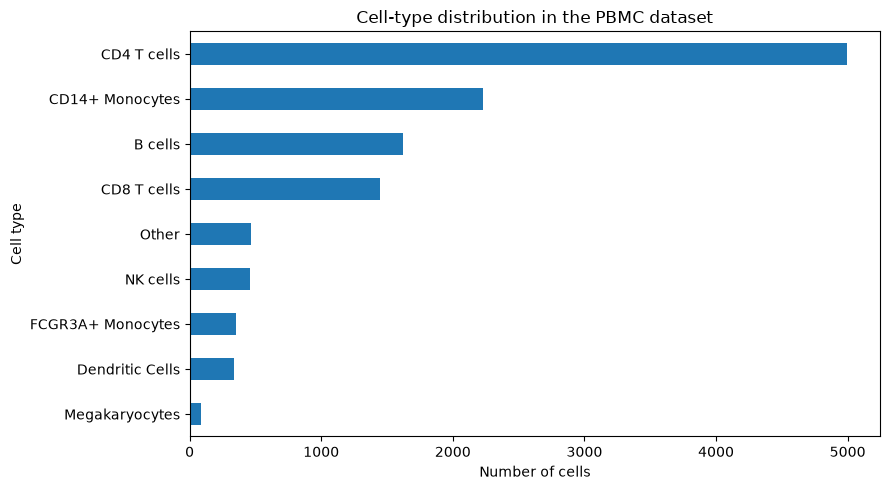

In [7]:
# Look at cell types
cell_counts= (
    adata.obs["str_labels"]
    .value_counts()
    .sort_values(ascending=False)
)
cell_counts
plt.figure(figsize=(9,5))
cell_counts.sort_values().plot(kind="barh")
plt.xlabel("Number of cells")
plt.ylabel("Cell type")
plt.title("Cell-type distribution in the PBMC dataset")
plt.tight_layout()
plt.show()

In [8]:
# Exploring the batches
print("Cells per batch:")
display(adata.obs["batch"].value_counts())
print("\nCell types by batch:")

batch_table = pd.crosstab(
    adata.obs["str_labels"],
    adata.obs["batch"]
)
display(batch_table)

Cells per batch:


batch
0    7982
1    4008
Name: count, dtype: int64


Cell types by batch:


batch,0,1
str_labels,,
B cells,1060,561
CD14+ Monocytes,1483,744
CD4 T cells,3364,1632
CD8 T cells,948,500
Dendritic Cells,209,130
FCGR3A+ Monocytes,224,127
Megakaryocytes,63,25
NK cells,285,172
Other,346,117


## Next steps:
- Batch 1 will be kept for a test set
- Batch 0 will be divided into training and validation subsets.


In [9]:
from sklearn.model_selection import train_test_split

batch_values = adata.obs["batch"].astype(str)

batch0_names = adata.obs_names[batch_values == "0"]
batch1_names = adata.obs_names[batch_values == "1"]

batch0_labels = adata.obs.loc[batch0_names, "str_labels"]

# using stratify so that the train and val subsets keep around  the same class proportions
train_names, val_names = train_test_split(
    batch0_names,
    test_size = 0.20,
    random_state = SEED,
    stratify = batch0_labels
)

test_names = batch1_names

train = adata[train_names].copy()
val = adata[val_names].copy()
test = adata[test_names].copy()

print("Training set:", train.shape)
print("Validation set:", val.shape)
print("Test set:", test.shape)

Training set: (6385, 3346)
Validation set: (1597, 3346)
Test set: (4008, 3346)


## Preprocessing
- Preprocessing will be performed to avoid information leakage, gene filtering and highly variable gene selection. These genes are applied to the validation and test sets.

In [13]:
from scipy.sparse import issparse

X_sample = train.X[:10, :10]

if issparse(X_sample):
    X_sample = X_sample.toarray()

print(X_sample)
print("\nMinimum:", X_sample.min())
print("Maximum:", X_sample.max())

# testing larger section of matrix
X_check = train.X[:100, :100]

if issparse(X_check):
    X_check = X_check.toarray()

print(
    "All sampled values integer-like:",
    np.allclose(X_check, np.round(X_check))
)

[[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 2. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [1. 1. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 2. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]

Minimum: 0.0
Maximum: 2.0
All sampled values integer-like: True


## Gene filtering and normalisation

- Removing genes that have been detected in very few cells as they provide little information for classification and can add noise.
- Expression values are normalised per cell to reduce differences in sequencing depth. A log transformation is applied to compress the highly skewed distribution of gene-expression values.
  

In [15]:
#  Filter genes using just the training set
sc.pp.filter_genes(train, min_cells=3)

genes_kept = train.var_names.copy()

# Apply same gene set to the validation and test data
val = val[:, genes_kept].copy()
test = test[:, genes_kept].copy()

print("Training set:", train.shape)
print("Validation set:", val.shape)
print("Test set:", test.shape)

for dataset in [train, val, test]:
    sc.pp.normalize_total(dataset, target_sum=1e4)
    sc.pp.log1p(dataset)

print("Genes after filtering:", train.n_vars)

Training set: (6385, 3346)
Validation set: (1597, 3346)
Test set: (4008, 3346)
Genes after filtering: 3346


## Highly variable gene selection
- Single-cell datasets contain many genes whose expression varies little across cells or contributes limited information for distinguishing cell populations.
- Next the 1000 most highly variable genes are selected using just the training data. The same gene set is applied to the validation and test datasets.


In [17]:
sc.pp.highly_variable_genes(
    train,
    n_top_genes=1000,
    flavor="seurat",
    subset=False
)

hvg_names = train.var_names[train.var["highly_variable"]]

train = train[:, hvg_names].copy()
val = val[:, hvg_names].copy()
test = test[:, hvg_names].copy()

print("Training set:", train.shape)
print("Validation set:", val.shape)
print("Test set:", test.shape)

Training set: (6385, 1000)
Validation set: (1597, 1000)
Test set: (4008, 1000)


## Preparing data for machine learning 

- The preprocessed AnnData expression matrices are converted into NumPy arrays for use with scikit-learn and PyTorch.
- Cell-type labels are encoded numerically and gene-expression features are standardised using statistics learned from just the training set.

In [19]:
from scipy.sparse import issparse

def to_dense_array(adata_object):
    X= adata_object.X

    if issparse(X):
        X = X.toarray()

    return np.asarray(X, dtype=np.float32)

X_train = to_dense_array(train)
X_val = to_dense_array(val)
X_test = to_dense_array(test)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (6385, 1000)
X_val: (1597, 1000)
X_test: (4008, 1000)


In [20]:
# Encode cell-type labels

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(train.obs["str_labels"])
y_val = label_encoder.fit_transform(val.obs["str_labels"])
y_test = label_encoder.fit_transform(test.obs["str_labels"])

label_mapping = pd.DataFrame({
    "Encoded label": range(len(label_encoder.classes_)),
    "Cell type": label_encoder.classes_
})

display(label_mapping)

,Encoded label,Cell type
0,0,B cells
1,1,CD14+ Monocytes
2,2,CD4 T cells
3,3,CD8 T cells
4,4,Dendritic Cells
5,5,FCGR3A+ Monocytes
6,6,Megakaryocytes
7,7,NK cells
8,8,Other


## Standardise the gene features

- Gene expression features are standardised to reduce differences in numerical scale between genes.
- The scaler is fitted using the training data only. The training means and standard deviations are applied to the validation and test sets so to prevent information leakage. 

In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Training mean:", X_train_scaled.mean())
print("Training standard deviation:", X_train_scaled.std())

Training mean: 5.400918e-10
Training standard deviation: 1.0


In [26]:
# Quick check
print("Feature matrices:")
print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

print("\nLabel vectors:")
print("Train:", y_train.shape)
print("Validation:", y_val.shape)
print("Test:", y_test.shape)

print("\nNumber of classes:", len(label_encoder.classes_))

Feature matrices:
Train: (6385, 1000)
Validation: (1597, 1000)
Test: (4008, 1000)

Label vectors:
Train: (6385,)
Validation: (1597,)
Test: (4008,)

Number of classes: 9


## Logistic Regression 
- Using a logistic regression classifier as a baseline.
- LR can work well on high dimensional gene-expression data and provide a useful benchmark to compare the neural network.
- Balanced class weights as used due to the cell type classed being imbalanced.
- Performance will be evaluated using overall accuracy and macro-averaged F1-score.

In [29]:
#Train baseline model
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import(
    accuracy_score,
    f1_score,
    classification_report
)

baseline_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state= SEED
)

baseline_model.fit(X_train_scaled, y_train)

# evaluate on validation data
val_predictions = baseline_model.predict(X_val_scaled)
val_accuracy = accuracy_score(y_val, val_predictions)
val_macro_f1 = f1_score(
    y_val,
    val_predictions,
    average = "macro"
)

print("Validation results")
print(f"Accuracy: {val_accuracy:.4f}")
print(f"Macro F1: {val_macro_f1:.4f}")

print(
    classification_report(
        y_val,
        val_predictions,
        target_names = label_encoder.classes_
    )
)

Validation results
Accuracy: 0.9580
Macro F1: 0.9063
                   precision    recall  f1-score   support

          B cells       0.99      1.00      1.00       212
  CD14+ Monocytes       0.95      0.99      0.97       297
      CD4 T cells       0.97      0.98      0.98       673
      CD8 T cells       0.92      0.91      0.91       190
  Dendritic Cells       0.97      0.88      0.93        42
FCGR3A+ Monocytes       0.93      0.87      0.90        45
   Megakaryocytes       0.80      0.67      0.73        12
         NK cells       0.91      0.91      0.91        57
            Other       0.90      0.78      0.84        69

         accuracy                           0.96      1597
        macro avg       0.93      0.89      0.91      1597
     weighted avg       0.96      0.96      0.96      1597



- Following the Logistic Regression baseline model, 95.8% validation accuracy was achieved as well as a macro-F1 score of 0.9606.
- Performance was strong across most cell types, although inn  rarer classes such as megakaryocytes there were lower scores.
- The difference between overall accuracy and macro-F1 shows the importance of class-specific evaluation in an imbalanced dataset.


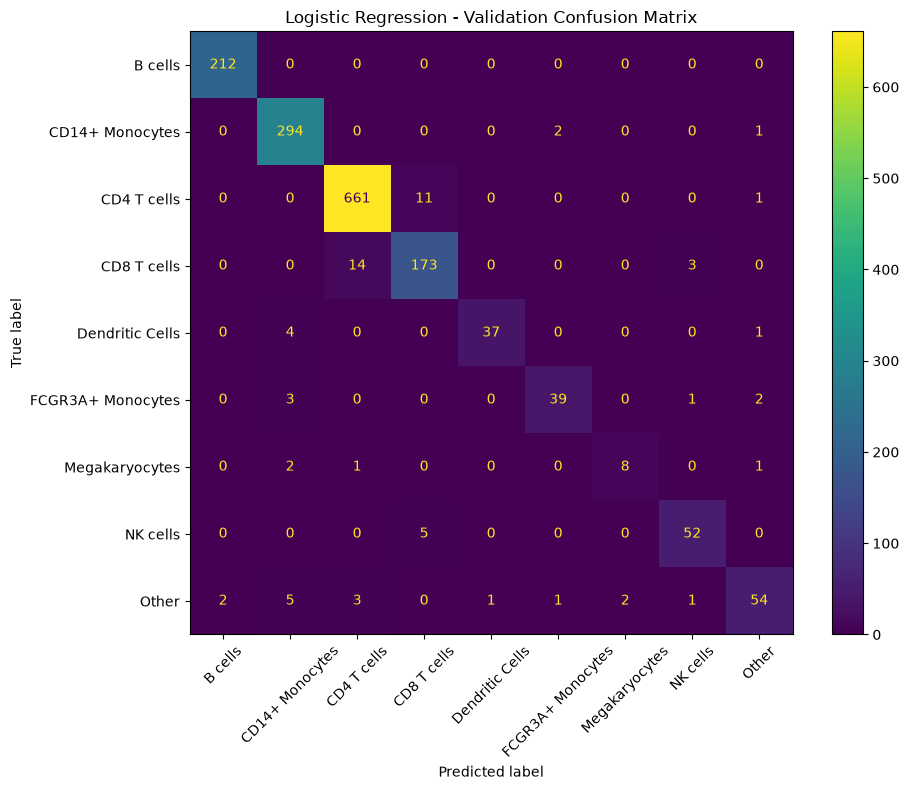

In [32]:
# Validation confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig,ax = plt.subplots(figsize=(10,8))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_predictions,
    display_labels=label_encoder.classes_,
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Logistic Regression - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

- There is strong classification across the major cell populations.
- Most of the erros occured between biologicaaly related cell types, especially CD4 and CD8 T cells, CD8 T cells and NK cells, and the two monocyte populations.
- Megakaryocytes had weaker performance, although it only had 12 validation cells.
- The "Other" category showed a broader pattern of missclassification.

In [35]:
# Evaluating LR on "Held-out" experimental batch
test_predictions = baseline_model.predict(X_test_scaled)
test_accuracy = accuracy_score(y_test, test_predictions)

test_macro_f1 = f1_score(
    y_test,
    test_predictions,
    average="macro"
)

print("Held-out test results")
print(f"Accuracy: {test_accuracy:4f}")
print(f"Macro F1: {test_macro_f1:4f}")

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=label_encoder.classes_
    )
)

Held-out test results
Accuracy: 0.949601
Macro F1: 0.919968
                   precision    recall  f1-score   support

          B cells       0.98      0.98      0.98       561
  CD14+ Monocytes       0.94      0.98      0.96       744
      CD4 T cells       0.97      0.97      0.97      1632
      CD8 T cells       0.89      0.90      0.89       500
  Dendritic Cells       0.96      0.90      0.93       130
FCGR3A+ Monocytes       0.95      0.83      0.88       127
   Megakaryocytes       0.88      0.92      0.90        25
         NK cells       0.95      0.95      0.95       172
            Other       0.88      0.76      0.82       117

         accuracy                           0.95      4008
        macro avg       0.93      0.91      0.92      4008
     weighted avg       0.95      0.95      0.95      4008



- The LR model generalised well to the held-out batch as it achieved 95% accuracy and a macro-F1 score of 0.920. Performance was close to the validation results despite the batch shift, however macro-F1 increased slightly.
- Most defined cell populations were classified with highh F1 scores. Lower performance was observed for FCGR3A+ monocytes, CD8 T cells and the "Other" category. This suggests that the model captures cell type associated expression patterns that transfer across the two experimental batches represented in this dataset. 

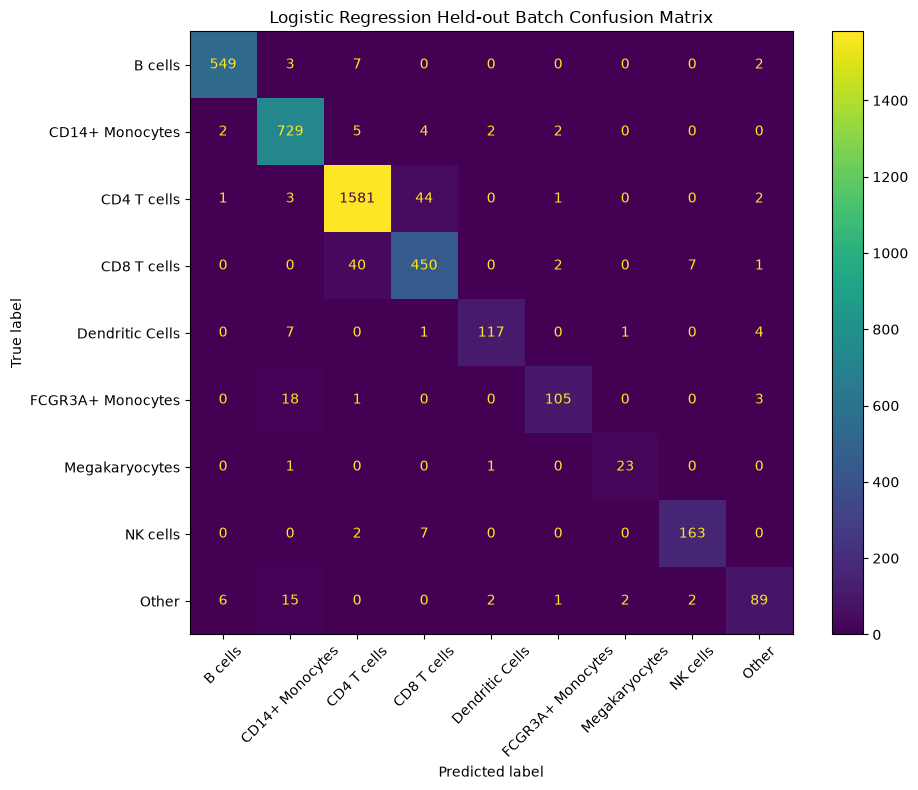

In [36]:
#  Held-out batch test confusion matrix
fig,ax = plt.subplots(figsize=(10,8))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=label_encoder.classes_,
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Logistic Regression Held-out Batch Confusion Matrix")
plt.tight_layout()
plt.show()

- The held-out confusion matrix above shows that most classification errors occured between biologically related cell populations. The largest confusion was between CD4 and CD8 T cells, while some FCGR3A+ monocytes were classified as CD14+ monocytes. NK cells also showed limited confusion with CD8 T cells.
- Teh "Other" category showed the broadest spread of misclassifications. While major populations like B cells, CD14+ monocytes and CD4 T cells were classified with high accuracy. Overall the patterns of errors remain biologically plausible on independent experimental batch.

## Neural Network classification with PyTorch

- A feed forward NN is traind to classify the nine cell types using the same 1000 highly variable genes used by the LR baseline.
- The model is trained on batch 0, with the validation subset used for model selectin and early stopping, while Batch 1 is reserved for final evaluation.

In [38]:
# convert data into PyTorch tensors
import torch 
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(SEED)

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor =torch.tensor(y_train, dtype=torch.long)
y_val_tensor =torch.tensor(y_val, dtype=torch.long)
y_test_tensor =torch.tensor(y_test, dtype=torch.long)

print("Training features:", X_train_tensor.shape)
print("Training labels:", y_train_tensor.shape)
print("Feature data type:", X_train_tensor.dtype)
print("Label data type:", y_train_tensor.dtype)

Training features: torch.Size([6385, 1000])
Training labels: torch.Size([6385])
Feature data type: torch.float32
Label data type: torch.int64


In [39]:
# create datasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset= TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Training samples: 6385
Validation samples: 1597
Test samples: 4008


In [41]:
# create DataLoaders
train_loader =DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

val_loader =DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False
)

test_loader =DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False
)

X_batch, y_batch=next(iter(train_loader))

print("Feature batch:",X_batch.shape)
print("Label batch:",y_batch.shape)

Feature batch: torch.Size([128, 1000])
Label batch: torch.Size([128])


## Neural Network Architecture
- The NN uses the 1000 selected gene-expression features as input and predicts one of nine cell types.
- Two hidden fully connected layers are used, with ReLU activation and dropout regularisation to reduce overfitting.

In [53]:
# add model
import torch.nn as nn

class CellTypeMLP(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()

        self.network=nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.30),
    
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.20),
    
            nn.Linear(64, num_classes)
        )
    def forward(self, x):
        return self.network(x)
# create model
input_dim = X_train_scaled.shape[1]
num_classes =len(label_encoder.classes_)

model=CellTypeMLP(
    input_dim=input_dim,
    num_classes=num_classes
)

print(model)

CellTypeMLP(
  (network): Sequential(
    (0): Linear(in_features=1000, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=9, bias=True)
  )
)


## Loss function and optimiser
- Because the cell type classes are imbalanced, class weights are calculated from the training labeld and incorporated into the loss function. This gives greater importance to errors made on rarer cell types.
- The model is optimised using AdamW with a small learning rate and weight decay.

In [54]:
# calculate class weights
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights=compute_class_weight(
    class_weight ="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights=torch.tensor(
    class_weights,
    dtype=torch.float32
)

print(class_weights)

# create loss function and optimiser
loss_function=nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer=torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print("Number of classes:", num_classes)
print("Class weights:", class_weights)
print("Loss function:", loss_function)
print("Optimizer:", optimizer)

tensor([ 0.8366,  0.5982,  0.2636,  0.9359,  4.2482,  3.9634, 13.9107,  3.1116,
         2.5612])
Number of classes: 9
Class weights: tensor([ 0.8366,  0.5982,  0.2636,  0.9359,  4.2482,  3.9634, 13.9107,  3.1116,
         2.5612])
Loss function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


## Model training and early stopping

- The NN is trained in mini-batches using the training subset. Performance is monitored on the validation set after each epoch using macro-averaged F1 score.
- Early stopping is used to retain the model state with the best validation macro-F1 score and to stop training when performance no longer improves.

In [55]:
from sklearn.metrics import f1_score
import copy

max_epochs=50
patience=8

best_val_f1=0.0
best_model_state= None
epochs_without_improvement = 0

training_losses =[]
validation_f1_scores=[]

for epoch in range(max_epochs):
    # train 
    model.train()
    running_loss=0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs=model(X_batch)
        loss=loss_function(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * X_batch.size(0)

    epoch_loss=running_loss/len(train_loader.dataset)
    training_losses.append(epoch_loss)

    # Validation
    model.eval()

    val_predictions_nn = []
    val_targets_nn = []

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            outputs = model(X_batch)
            predictions = torch.argmax(outputs, dim=1)

            val_predictions_nn.extend(predictions.cpu().numpy())
            val_targets_nn.extend(y_batch.cpu().numpy())

    val_f1 = f1_score(
        val_targets_nn,
        val_predictions_nn,
        average="macro"
    )

    validation_f1_scores.append(val_f1)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Validation Macro F1: {val_f1:.4f}"
    )

    # Early stopping
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

# Restore the best-performing model
model.load_state_dict(best_model_state)

print(f"\nBest validation Macro F1: {best_val_f1:.4f}")

Epoch 01 | Loss: 1.2181 | Validation Macro F1: 0.8817
Epoch 02 | Loss: 0.2103 | Validation Macro F1: 0.9079
Epoch 03 | Loss: 0.0840 | Validation Macro F1: 0.9135
Epoch 04 | Loss: 0.0389 | Validation Macro F1: 0.9075
Epoch 05 | Loss: 0.0237 | Validation Macro F1: 0.9086
Epoch 06 | Loss: 0.0147 | Validation Macro F1: 0.9124
Epoch 07 | Loss: 0.0103 | Validation Macro F1: 0.9042
Epoch 08 | Loss: 0.0080 | Validation Macro F1: 0.9045
Epoch 09 | Loss: 0.0070 | Validation Macro F1: 0.9031
Epoch 10 | Loss: 0.0066 | Validation Macro F1: 0.8981
Epoch 11 | Loss: 0.0048 | Validation Macro F1: 0.9037
Early stopping triggered.

Best validation Macro F1: 0.9135


In [56]:
# calculate best epoch without retraining
best_epoch=np.argmax(validation_f1_scores)+1
print("Best epoch:",best_epoch)
print(f"Best validation Macro F1:{best_val_f1:.4f}")

Best epoch: 3
Best validation Macro F1:0.9135


- The NN reached its best validation macro-F1 score of 0.914 at epoch 3, slightly excedding the LR baseline of 0.906.
- Training loss continued to decrease after this point while validation performance plateaued and declined, which indicated increasing overfitting to the training data. Early stopping therefore retained the model parameters from the best-performing validation epoch.

In [58]:
# evaluate NN on held-out batch
model.eval()
test_predictions_nn=[]
test_targets_nn=[]

with torch.no_grad():
    for X_batch, y_batch in test_loader:

        outputs=model(X_batch)
        predictions=torch.argmax(outputs, dim=1)

        test_predictions_nn.extend(predictions.cpu().numpy())
        test_targets_nn.extend(y_batch.cpu().numpy())

nn_test_accuracy=accuracy_score(
    test_targets_nn,
    test_predictions_nn
)

nn_test_macro_f1=f1_score(
    test_targets_nn,
    test_predictions_nn,
    average="macro"
)

print("Neural network held-out results")
print(f"Accuracy: {nn_test_accuracy:.4f}")
print(f"Macro F1: {nn_test_macro_f1:.4f}")

print(
    classification_report(
        test_targets_nn,
        test_predictions_nn,
        target_names=label_encoder.classes_
    )
)

Neural network held-out results
Accuracy: 0.9528
Macro F1: 0.9365
                   precision    recall  f1-score   support

          B cells       0.98      0.98      0.98       561
  CD14+ Monocytes       0.96      0.97      0.97       744
      CD4 T cells       0.98      0.95      0.96      1632
      CD8 T cells       0.85      0.96      0.90       500
  Dendritic Cells       0.98      0.92      0.94       130
FCGR3A+ Monocytes       0.92      0.87      0.89       127
   Megakaryocytes       0.92      0.96      0.94        25
         NK cells       0.95      0.97      0.96       172
            Other       0.88      0.87      0.88       117

         accuracy                           0.95      4008
        macro avg       0.94      0.94      0.94      4008
     weighted avg       0.95      0.95      0.95      4008



## NN held-out performance
- The NN achieved 95.3% accuracy and a macro-F1 score of 0.937 on the held-out experimental batch, compared wit 95.0% accuracy and 0.920 macro-F1 for LR.
- The improvement in overall accuracy was modest, while the larger increase in macro-F1 indicated more balanced performance across cell types. Improvements were particularly evident for several less frequent populations, including megakaryocyted and the "Other" category.
- These results show that both models generalised well across the 2 experimental batches, with the NN providing a modest advantage in class-balanced predictive performance.

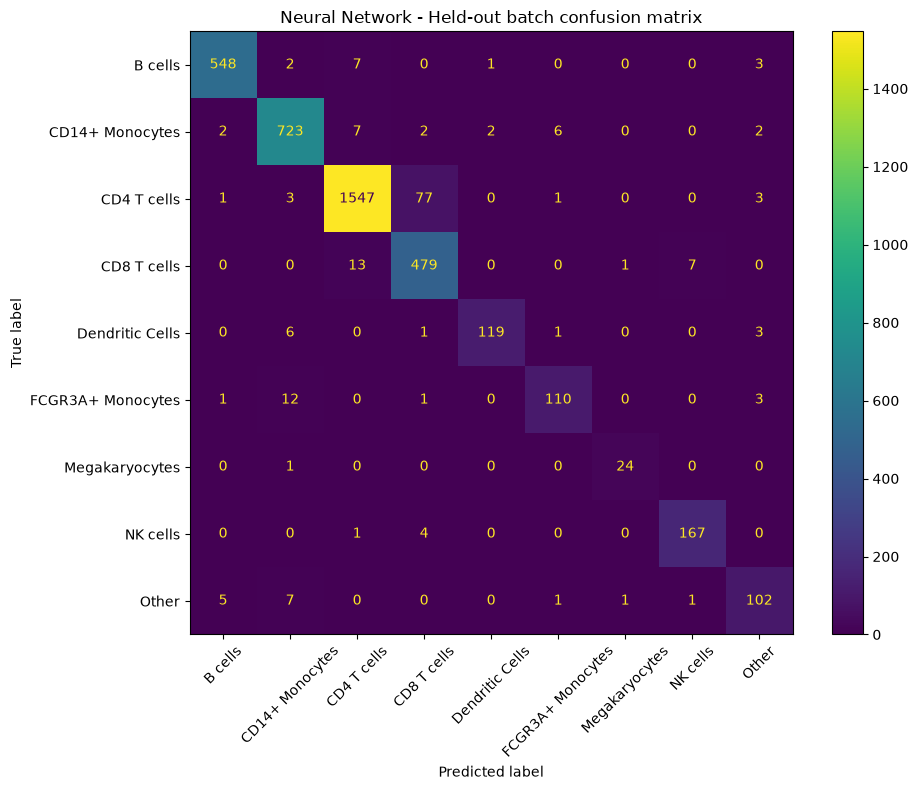

In [59]:
# NN confusion matrix
fig, ax = plt.subplots(figsize=(10,8))

ConfusionMatrixDisplay.from_predictions(
    test_targets_nn,
    test_predictions_nn,
    display_labels=label_encoder.classes_,
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Neural Network - Held-out batch confusion matrix")
plt.tight_layout()
plt.show()

In [61]:
# comparison table
comparison_df=pd.DataFrame({
    "Model":[
        "Logistic Regression",
        "Neural Network"
    ],
    "Validation Macro F1":[
        val_macro_f1,
        best_val_f1
    ],
    "Held-out Accuracy":[
        test_accuracy,
        nn_test_accuracy
    ],
    "Held-out Macro F1":[
        test_macro_f1,
        nn_test_macro_f1
    ]
})

comparison_df.round(4)

,Model,Validation Macro F1,Held-out Accuracy,Held-out Macro F1
0,Logistic Regression,0.9063,0.9496,0.9200
1,Neural Network,0.9135,0.9528,0.9365


## Model comparison

- Bothh models achieved strong performance on the held-out experimental batch. The NN slighlty improved overall accuracy from 95.0% to 95.3%, while macro-F1 increased from 0.920 to 0.937.
- The larger improvement in macro-F1 suggests that the NN provided more balanced performance across cell types, several less frequent populations. However, the improvement over LR was modest, showing that the similar linear baseline already captured much of the cell-type associated signal in the selected gene-expression features.
- The NN provided the strongest predictive performance, but at the cost of increased model complexity and a greater tendency to overfit the training data.

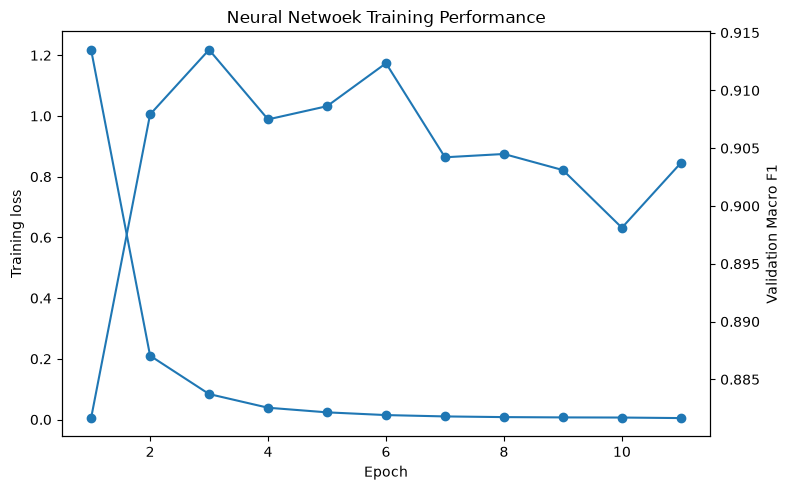

In [62]:
epochs = range(1, len(training_losses)+1)

fig, ax1= plt.subplots(figsize=(8,5))

ax1.plot(
    epochs,
    training_losses,
    marker="o",
    label="Training loss"
)

ax1.set_xlabel("Epoch")
ax1.set_ylabel("Training loss")

ax2=ax1.twinx()

ax2.plot(
    epochs,
    validation_f1_scores,
    marker="o",
    label="Validation Macro F1"
)
ax2.set_ylabel("Validation Macro F1")

plt.title("Neural Netwoek Training Performance")
plt.tight_layout()
plt.show()

## Model interpretation with Integrated Gradients
- I.G is used to investigate which gene expression features contributed most strongly to the NN cell type predictions.
- Attributions are calculated for correctly classified cells from the held-out experimental batch. A zero baseline is used in the standardised feature space, representing the training set mean expression level for each selected gene.
- These attributions describe contributions to the model's predictions and should not be interpreted as equivalent to differential gene expression.

In [67]:
# captum
from captum.attr import IntegratedGradients
ig= IntegratedGradients(model)

model.eval()
gene_ids=train.var_names.to_numpy()

print("Number of model features:", X_test_tensor.shape[1])
print("Number of gene IDs:", len(gene_ids))

print(train.var.columns)

gene_symbols=(
    train.var["gene_symbols"]
    .fillna(train.var_names.to_series())
    .astype(str)
    .to_numpy()
)

print(gene_symbols[:10])

Number of model features: 1000
Number of gene IDs: 1000
Index(['gene_symbols', 'n_counts-0', 'n_counts-1', 'n_counts', 'n_cells',
       'highly_variable', 'means', 'dispersions', 'dispersions_norm'],
      dtype='object')
['PLCH2' 'NOL9' 'DNAJC11' 'CA6' 'SPSB1' 'UBIAD1' 'FBXO2' 'DHRS3' 'C1QB'
 'ID3']


In [68]:
test_predictions_nn=np.asarray(test_predictions_nn)
test_targets_nn=np.asarray(test_targets_nn)

correct_mask=test_predictions_nn == test_targets_nn

print("Correctly classified cells:", correct_mask.sum())
print("Total test cells:", len(test_targets_nn))

Correctly classified cells: 3819
Total test cells: 4008


## Gene-level attribution
- IG attributions are calculated for up to 100 correctly classified cells from each cell type in the held-out batch. Attributions are calculated relative to a zero baseline in the standardised feature space, corresponding approximately to mean training set expression for each gene.
- Positive attributions indicated features that contributed toward the model's prediction of a given cell type. Attributions reflect model behaviour and are not equivalent to differential gene expression statistics.

In [70]:
# IG for correctly classified held-out cells

rng=np.random.default_rng(SEED)

attribution_results={}

for class_idx, class_name in enumerate(label_encoder.classes_):
    class_indices=np.where(
        (test_targets_nn == class_idx) &
        (test_predictions_nn == class_idx)
    )[0]
    n_samples=min(100, len(class_indices))

    selected_indices=rng.choice(
        class_indices,
        size=n_samples,
        replace=False
    )

    class_inputs=X_test_tensor[selected_indices]
    
    baseline=torch.zeros_like(class_inputs)
    
    attributions=ig.attribute(
        class_inputs,
        baselines=baseline,
        target=class_idx,
        n_steps=50,
        internal_batch_size=256
    )

    # avg gene attributions across selected cells
    mean_attribution=attributions.mean(dim=0).detach().cpu().numpy()
    attribution_results[class_name]=mean_attribution
    print(f"{class_name}:{n_samples}cells")

B cells:100cells
CD14+ Monocytes:100cells
CD4 T cells:100cells
CD8 T cells:100cells
Dendritic Cells:100cells
FCGR3A+ Monocytes:100cells
Megakaryocytes:24cells
NK cells:100cells
Other:100cells


In [72]:
# extract top genes
top_gene_tables={}

for class_name, mean_attribution in attribution_results.items():
    attribution_df=pd.DataFrame({
        "Gene": gene_symbols,
        "Attribution": mean_attribution
    })
    attribution_df=(
        attribution_df
        .sort_values("Attribution", ascending=False)
        .head(10)
        .reset_index(drop=True)
    )
    top_gene_tables[class_name]=attribution_df

    print(f"\n{class_name}")
    display(attribution_df)


B cells


,Gene,Attribution
0,CD79A,0.383840
1,CD79B,0.286894
2,VPREB3,0.280508
3,HLA-DOB,0.271037
4,BANK1,0.266591
5,CD19,0.221945
6,SPIB,0.194431
7,RALGPS2,0.178452
8,CD3E,0.173159
9,TSPAN13,0.172813



CD14+ Monocytes


,Gene,Attribution
0,S100A12,0.259025
1,LGALS2,0.197315
2,CSTA,0.183787
3,CD14,0.182739
4,EVL,0.180286
5,MS4A6A,0.156202
6,MNDA,0.152393
7,LTB,0.150322
8,CLEC7A,0.135943
9,FCN1,0.124792



CD4 T cells


...

,Gene,Attribution
0,TUBB1,0.713563
1,GNG11,0.709921
2,PPBP,0.605637
3,GP9,0.559249
4,PF4,0.491852
5,TMEM40,0.483165
6,LCN2,0.434630
7,HIST1H2AC,0.394370
8,SELP,0.382732
9,CLDN5,0.357396



NK cells


,Gene,Attribution
0,KLRF1,0.596908
1,GZMB,0.312525
2,PRF1,0.268727
3,IL2RB,0.265549
4,MATK,0.254989
5,PRSS23,0.240015
6,CD160,0.236536
7,KLRB1,0.230612
8,AKR1C3,0.204464
9,NKG7,0.157653



Other


,Gene,Attribution
0,SCT,0.656444
1,PTPRS,0.346688
2,LILRA4,0.319583
3,DNASE1L3,0.289128
4,MS4A6A,0.210570
5,TSPAN13,0.196128
6,SPIB,0.178109
7,S100A12,0.139134
8,IRF8,0.131817
9,GZMB,0.129053


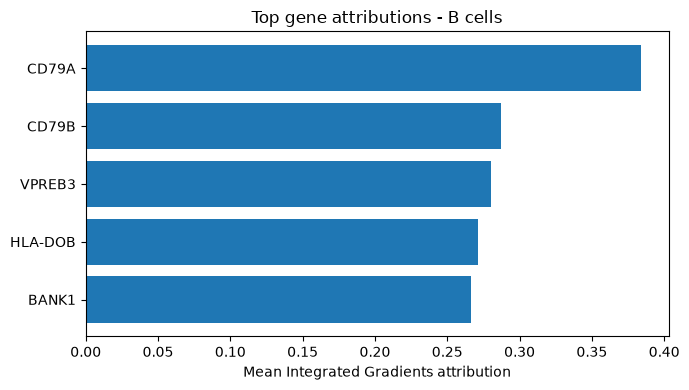

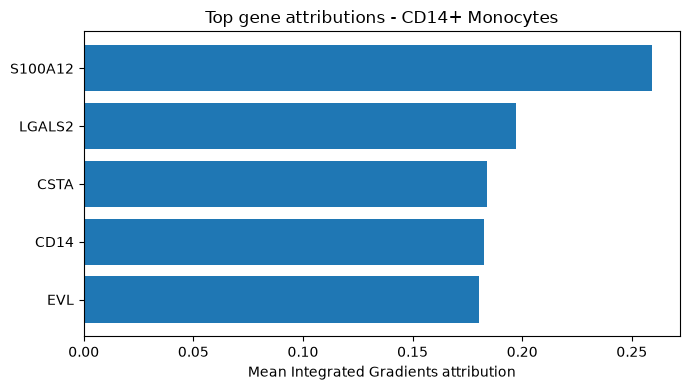

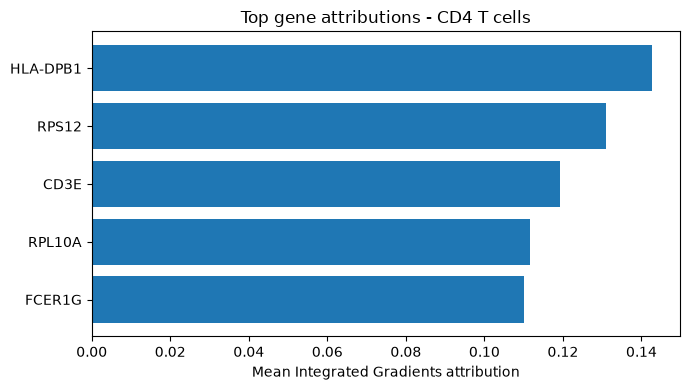

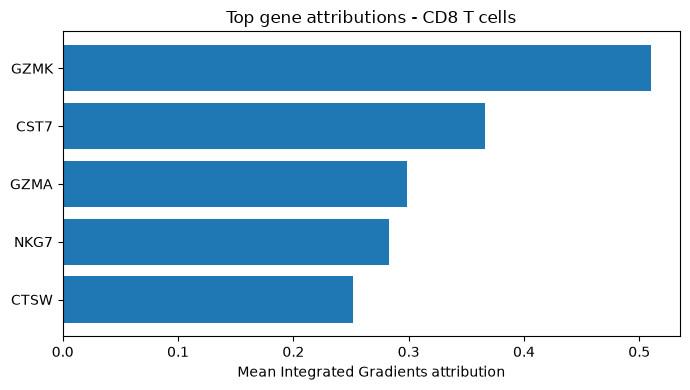

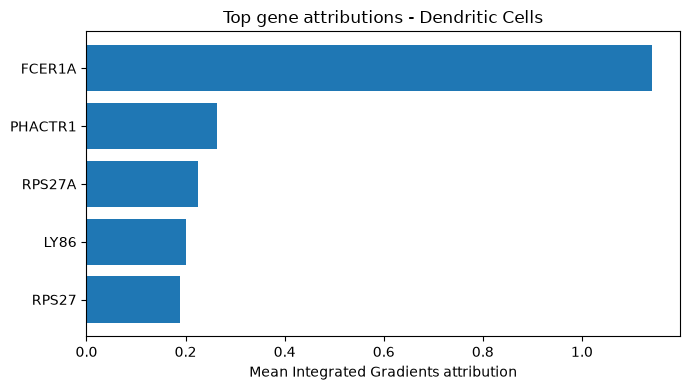

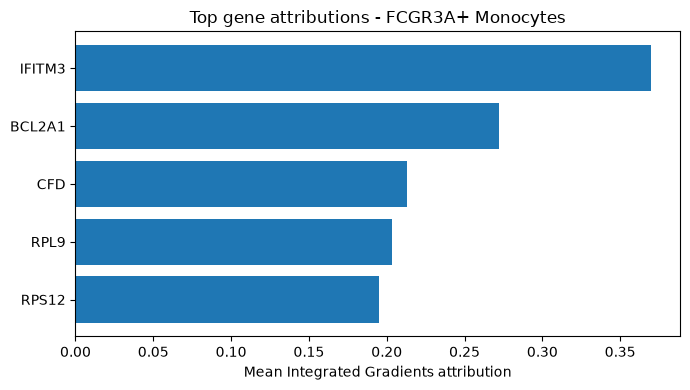

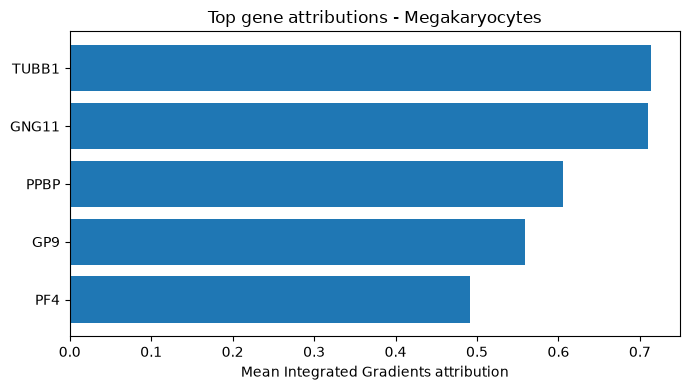

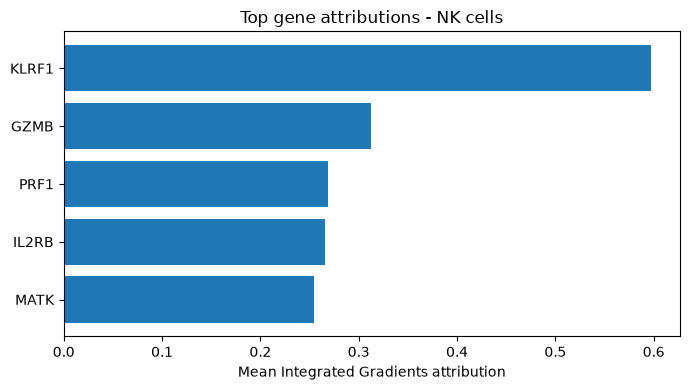

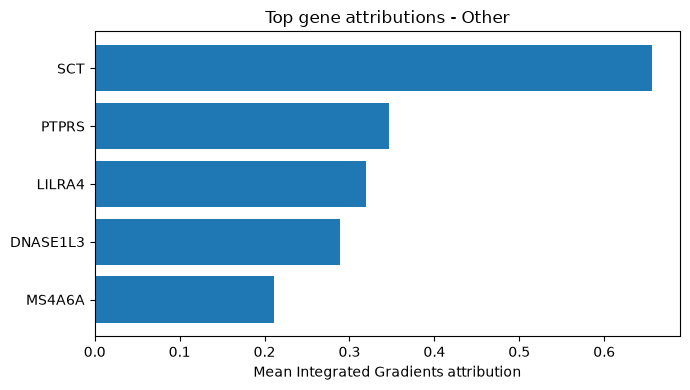

,Cell_Type,Gene,Attribution
0,B cells,CD79A,0.383840
1,B cells,CD79B,0.286894
2,B cells,VPREB3,0.280508
3,B cells,HLA-DOB,0.271037
4,B cells,BANK1,0.266591
...,...,...,...
85,Other,TSPAN13,0.196128
86,Other,SPIB,0.178109
87,Other,S100A12,0.139134
88,Other,IRF8,0.131817


,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,Dendritic Cells,FCGR3A+ Monocytes,Megakaryocytes,NK cells,Other
1,CD79A,S100A12,HLA-DPB1,GZMK,FCER1A,IFITM3,TUBB1,KLRF1,SCT
2,CD79B,LGALS2,RPS12,CST7,PHACTR1,BCL2A1,GNG11,GZMB,PTPRS
3,VPREB3,CSTA,CD3E,GZMA,RPS27A,CFD,PPBP,PRF1,LILRA4
4,HLA-DOB,CD14,RPL10A,NKG7,LY86,RPL9,GP9,IL2RB,DNASE1L3
5,BANK1,EVL,FCER1G,CTSW,RPS27,RPS12,PF4,MATK,MS4A6A
6,CD19,MS4A6A,RPS29,KLRG1,HLA-DMB,RPL32,TMEM40,PRSS23,TSPAN13
7,SPIB,MNDA,CD3D,IL32,RPS12,RPS27A,LCN2,CD160,SPIB
8,RALGPS2,LTB,RPS25,DUSP2,RPS29,RPS29,HIST1H2AC,KLRB1,S100A12
9,CD3E,CLEC7A,RPS8,CD8A,LGALS2,RPL30,SELP,AKR1C3,IRF8
10,TSPAN13,FCN1,IL32,GZMH,RPS25,RPS27,CLDN5,NKG7,GZMB


In [75]:
# plot these attributions
for class_name, attribution_df in top_gene_tables.items():

    top5=attribution_df.head(5).sort_values(
        "Attribution",
        ascending=True
    )
    plt.figure(figsize=(7,4))
    plt.barh(
        top5["Gene"],
        top5["Attribution"]
    )
    plt.xlabel("Mean Integrated Gradients attribution")
    plt.title(f"Top gene attributions - {class_name}")
    plt.tight_layout()
    plt.show()

# combine top gene attributions into one table
top_genes_summary=pd.concat(
    [
        df.assign(Cell_Type=class_name)
        for class_name, df in top_gene_tables.items()
    ],
    ignore_index=True
)
top_genes_summary=top_genes_summary[
    ["Cell_Type", "Gene", "Attribution"]
    ]
display(top_genes_summary)

top_genes_wide=pd.DataFrame({
    class_name:df["Gene"].tolist()
    for class_name, df in top_gene_tables.items()
})
top_genes_wide.index=range(1,11)
display(top_genes_wide)

## Biological Intepretation of gene attributions
- IG identified biologically plausible gene-level contributions for several cell populations. B-cell predictions were strongly associated with gene including CD79A, CD79B, BANK1 and CD19, while CD14+ monocyte predictions included S100A12, CD14 and FCN1.
- The CD8 T-cell attribution profile contained cytotoxic and T-cell associated genes incl. GZMK, NKG7, CTSW, CD8A and GZMH. Similarly, NK-cell predictions were strongly influenced by genes incl. KLRF1, GZMB, PRF1, CD160 and NKG7. Megakartocyte predictions showed a particularly clear platelet-associated signature, incl. TUBB1, PPBP, GP9 and PF4.
- Dendritic cell predictions incl. FCER1A and antigen presentation associated genes, while the CD4 T-cell profile contained T-cell genes such as CD3D and
CD3E but also several less cell-type-specific features. The FCGR3A+ monocyte profile was similarly less clearly defined than the CD14+ monocyte profile.
- The heterogeneous "Other" category included LILRA4, SPIB, IRF8 and GZMB, which suggests that some cells within this group may have a plasmacytoid-dendritic-cell like expression profile.
- Overall, the attribution results suggest that the NN learned biologically meaningful expression patterns rather than relying entirely on non-specific features. However, IG measures feature contributions to the model's predictions and should not be interpreted as differential gene expression or evidence of causal biological relationships.

## Limitations
Several limitations should be consided:
- The analysis uses a single PMBC dataset containing 2 experimental batches. Holding one batch out provides a useful test of cross-batch generalisation, but performance may differ on independent datasets generated using different samples, laboratories or sequencing protocols.
- The NN architecture was intentionally simple and no extensive hyperparameter optimisation was performed. The aim was to compare a straightforward NN with a strong classical baseline rather than to maximise predictive performance.
- The dataset contains pre-assigned cell type labels, meaning model performance depends on the quality and biological resolution of those labels. The "Other" category is difficult to interpret.
- IG attributions are dependent on the trained model and the chosen baseline. They describe which input features contributed to model predictions and should not be interpreted as differential expression, casual relationships or definitive biological markers.

## Conclusion
- This project investigated whether cell types could be classified from single-cell RNA-seq expression profiles while retaining interpretable gene-level information.
- Both LR and a feed-forward NN generalised well to a held-out experimental batch. LR achieved 95.0% accuracy and a macro-F1 of 0.920, while the NN achieved 95.3% accuracy and a macro-F1 score of 0.937. The relatively small difference in accuracy showed that the linear baseline already captured much of the predictive signal, although the NN provided more balanced performance across cell types.
- IG identified biologically plausible contributions for several populations, incl B-cell, monocyte, cytotoxic T-cell, NK-cell and megakaryocyte-asscociated geneed. This demonstrates how predictive modelling and model interpretation can be combined to investigate bothe classification performance and the biological features influencing model decisions.
- Overall, the project demonstrates a reporducible workflow combining batch-aware experimental design, classical machine learning, neural network classification and interpretable deep learning for single-cell RNA-seq data.